# Part B: Flow Matching from Scratch!
Student notebook: implement the marked exercises using [the assignment](partb.html).


**Conventions:** MNIST pixels are in $[0,1]$. Flow time goes from Gaussian noise
at 0 to data at 1. Predict velocity $x_1-x_0$, not noise. Part B uses
$v_u+\gamma(v_c-v_u)$ with $\gamma=5$; this is different from Part A's guidance convention.

## Start here
1. Select a **GPU**: Colab **Runtime → Change runtime type**, or Kaggle **Settings → Accelerator**. Enable Internet on Kaggle.
2. Run the **Setup** cell below. Everything needed is included or downloaded automatically.
3. Complete the exercises below and run their cells.

**No ZIP upload, Google Drive mount, helper-file edits, or cache configuration is needed.**
Use a fresh runtime when switching between Part A and Part B. Downloads are automatically
reused within the session. Save your notebook with outputs before disconnecting.

In [3]:
#@title Setup (run once)
# Supplied support code and images are embedded: no separate files are needed.
import os, sys, time, io, base64, zipfile, hashlib
from pathlib import Path
_cs180_started = time.perf_counter()
IN_COLAB = 'google.colab' in sys.modules
IN_KAGGLE = Path('/kaggle/working').is_dir()
PART = 'partb'
_work = Path('/content/cs180-hw3') if IN_COLAB else (Path('/kaggle/working') if IN_KAGGLE else Path.cwd())
_work.mkdir(parents=True,exist_ok=True)
_support = base64.b64decode('UEsDBBQAAAAIAAAAIVx0NVtTYAUAACkNAAAOAAAAY29sYWJfc2V0dXAucHm1V11T3DYUfd9foZIH2YkRENI23Yk7QwlJmBSyA6QvDOPR2nd3VWzJleSFLcN/75VkG8MCaTPTfVivdaVzv8/VbmxsHFxD3lgoyHRFpLIwVeqSGLBNTfjMgibG8rmQc2IXQExT10pbMm1kUQIpVc7LcsU2NjZGovKS8CjFlFVgecEt7yTKjGZaVaTmdoHydieZ4Gu3xTTTWqscjOlXVmY0yjSgEdri869GaLQ1JecXo9GogBkREmVlmVXCGDQzuuISvYnHI4IfNOwwyMlMaGMT54UkDgchCSctMlGyXJGZ0ugSL1BBzfNLPgeD+7kl+YLLORTeTwc7L9WUl2TNLi8Us3VBsMZ9NBcGyEkjrajgQGulIzrplF2BBtLUGDU0QUhULgxpI8LISWurS8S+KvkU04Q+K0loD//Ih04BHQN0VTdSukz67I4JfUUTQtmfSshozeI49phtxpx9eJKZGnIxE6BNl77TbuUUrD/R5iHFBHkAjGkbzMSddm6FFDFhoTJRfBcbq1djskRw9CldLyTWiqIWL+4PwnUO9WO1x9rQHiv7QWHN+oDf6ThWEnoQzFu7TjDqTkTQ9m4JW8OZPnQ3cv7E485jxusaZNFZ98pLu4pwx9t9g1rAPGjpX1+QQ5mXTQEYBC6NsGIJpAAHCDIXWBsRsDkjVl2CFH+jUXHiQRupoQz14r3HH5UqmhIM88ChnjOtlDXpjeQVYBJLYSPKaHy+feET5Jadd9htrD1960+H0klvbvtcBnHS9weeeiTsnTgrhLFaTBuLMcRcr+ccYxMguwgPDR6TXGGjyOYuS4N6crs7ReN7HeALKdh+3u64+E8F9T1FVXOkLXew1kJifFvicQ3X81Zvruu8vvnawmhb7o4EWb6A/DJzHBudu9yA52o+xQTQzYomtBY1frcUiL82N1ERWJq8bDEv2grsnRByyUvhGAZxER+TsdanqvTsEwL4RJtKuPpfW9ThP2xPXCM/pATNG69T7IP2i7+Ti9uscVewWH1VXQL2VIITzxMv7uelBl6sNh9OinZIjJ9n42c59xV9juWVzCH5BteH8dbIboLPuZCMnC2gm5NDi68EzsWpmwyNwQDSuB2p2HQzMW80YDA1zsxuxA75KP3ASwNtVbhmTd0gZ/lV0RaUry6/GCmsXLkUWkmGZqEG3pTYIPunO2+3s/29/U8H2fvDE5ogVUQOaosyf5rG8QCLVZeF0M4kkMhlZ7qBBK6RXzJ16d/C3ieUffqQffpydBCUeLwtumjmbqrNeO5UPXc6mDo5+XI0OQsW3wPCfq1qm0E1haJARPOv4M5O9g6PH0HDCSDcnP4GyORw8jB4nTnICnHfAI9l764HXpDPAHWoNGrI/tf3e5uu7LEBkGZw3uh8seW/lyLMxmGDINHx3LIeLUz29IZW3Nalco1Ox/TXdJf9nLx7gwQ1wZJTV37tF/aa3g7b2xVbmlL34PQ+obc3hnA1im6oH5LIThXSDYKl6Rv24w7bRQWDnG4umqkXbrPdn1BZQkFIVRuvfZu9Td7t0Ns7hnriIjngzxCNtYUQmOGk98ssbwrOhMn4kovSkfaQRB/jnlMoIXe30o+Tr4TnOb5qjliOjAMV4O/PfD5H/u8usn2vu/Z1wFiLtUkHFszBYu6XIofMyUBbLIBoOx7OKlSII8kfZe4ykNA/TvaOyEfxGy5rR8tREFqFMcoqqJRebb1++XJ3O9mJ70FNVmdON54LNmRZOxOyLKGDeHUbwttw2z24391fjEAAeMI/+8p+omA6QxyL7uEb3ti8QjJDyra7r0lk4doS7ARV4P8bLt3dyd0n8CICZdwFMtzOgurRP1BLAQIUAxQAAAAIAAAAIVx0NVtTYAUAACkNAAAOAAAAAAAAAAAAAACAAQAAAABjb2xhYl9zZXR1cC5weVBLBQYAAAAAAQABADwAAACMBQAAAAA=')
assert hashlib.sha256(_support).hexdigest() == 'ba2fae2d7267a416d94cd581fd0ac5eadf93d641618063a782d0dffdc36d31cd', 'Damaged notebook support data'
with zipfile.ZipFile(io.BytesIO(_support)) as _archive:
    for _entry in _archive.infolist():
        _target=(_work/_entry.filename).resolve()
        if _work.resolve() not in _target.parents: raise ValueError('Unsafe embedded path')
    _archive.extractall(_work)
os.chdir(_work)
if str(_work) not in sys.path: sys.path.insert(0,str(_work))
from colab_setup import configure
configure(PART,install_dependencies=IN_COLAB or IN_KAGGLE)
print('Setup complete. Continue with the notebook below.')

GPU: Tesla T4 VRAM GiB: 14.6
PyTorch: 2.11.0+cu128 torchvision: 0.26.0+cu128
Local cache: /kaggle/working/.cache
Setup complete. Continue with the notebook below.


## Setup environment

In [4]:
# Install requirements-partb.txt in the active environment before running.
# No automatic package changes to an existing GPU environment.
import sys
assert sys.version_info >= (3,9), 'Use Python 3.9 or newer.'

In [5]:
import os, json, time, random
from pathlib import Path
from typing import Optional
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

SEED = 180
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(4)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
GROUP = os.environ.get('PARTB_GROUP','all')
assert GROUP in ('all','denoise','time','class','no_scheduler')
OUT = Path('results/partb') / GROUP
OUT.mkdir(parents=True, exist_ok=True)
metrics = {'seed':SEED,'group':GROUP,'torch':torch.__version__,
           'device':str(device),'gpu':torch.cuda.get_device_name() if device.type=='cuda' else None,
           'visible_devices':os.environ.get('CUDA_VISIBLE_DEVICES'),
           'precision':'float32 with TF32 convolution/matmul enabled'}
print(metrics)
train_dataset = MNIST('data', train=True, download=True, transform=ToTensor())
test_dataset = MNIST('data', train=False, download=True, transform=ToTensor())
assert len(train_dataset)==60000 and len(test_dataset)==10000

def show_grid(images, title, filename, nrow=10):
    images = images.detach().float().cpu()
    grid = make_grid(images.clamp(0, 1), nrow=nrow, padding=2)
    fig, ax = plt.subplots(figsize=(12, max(2, len(images)/nrow*1.15)))
    ax.imshow(grid.permute(1, 2, 0)); ax.set_title(title); ax.axis('off')
    fig.tight_layout(); fig.savefig(OUT / filename, dpi=120)
    plt.show(); plt.close(fig)


def loss_plot(losses, name):
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.plot(losses, alpha=.4, linewidth=.5)
    window = min(100, len(losses))
    smooth = torch.tensor(losses).unfold(0, window, 1).mean(1)
    ax.plot(range(window-1, len(losses)), smooth, linewidth=1)
    ax.set(xlabel='Optimizer step', ylabel='Mean squared error', title=name)
    fig.tight_layout(); fig.savefig(OUT / (name+'_loss.png'), dpi=120)
    plt.show(); plt.close(fig)


def make_loader(batch_size, seed=180):
    # Decode/normalize once; augmentation noise is still drawn fresh in each step.
    dataset = torch.utils.data.TensorDataset(train_dataset.data[:, None].float()/255,
                                             train_dataset.targets)
    return DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=0,
                      pin_memory=device.type == 'cuda',
                      generator=torch.Generator().manual_seed(seed))

{'seed': 180, 'group': 'all', 'torch': '2.11.0+cu128', 'device': 'cuda', 'gpu': 'Tesla T4', 'visible_devices': None, 'precision': 'float32 with TF32 convolution/matmul enabled'}


100%|██████████| 9.91M/9.91M [00:00<00:00, 135MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 13.9MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 39.6MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 14.5MB/s]


## Neural Network Resources

In this part, you will build and train a [UNet](https://arxiv.org/abs/1505.04597), which is more complex than the MLP you implemented in the NeRF project.  We provide all class definitions you may need (but feel free to add or modify them as necessary).  

Instead of asking ChatGPT to write everything for you, please consult the following resources when you get stuck — they will help you understand how and why things work under the hood.

- PyTorch Documentation — [`Conv2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Conv2d.html), [`ConvTranspose2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.ConvTranspose2d.html), and [`AvgPool2d`](https://docs.pytorch.org/docs/stable/generated/torch.nn.AvgPool2d.html).
- PyTorch Documentation - [`torchvision.datasets.MNIST`](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.MNIST.html), the dataset we gonna use, and [`torch.utils.data.DataLoader`](https://docs.pytorch.org/docs/stable/data.html), the off-the-shell dataloader we can directly use.
- PyTorch [tutorial](https://docs.pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html) on how to train a classifier on CIFAR10 dataset. The structure of your training code will be very similar to this one.

# Part 1: Training a Single-step Denoising UNet


# Part 1.1: Implementing the UNet

## Implementing Simple and Composed Ops

In [6]:
class Conv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=1, padding=1)
        self.bn = nn.BatchNorm2d(out_channels)
        self.gelu = nn.GELU()
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        x = self.gelu(self.bn(self.conv(x)))
        return x
        # ===== end of code ====
        raise NotImplementedError()


class DownConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=2, padding=1)
        self.bn = nn.BatchNorm2d(out_channels)
        self.gelu = nn.GELU()
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        x = self.gelu(self.bn(self.conv(x)))
        return x
        # ===== end of code ====
        raise NotImplementedError()


class UpConv(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.conv = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=4, stride=2, padding=1)
        self.bn = nn.BatchNorm2d(out_channels)
        self.gelu = nn.GELU()
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        x = self.gelu(self.bn(self.conv(x)))
        return x
        # ===== end of code ====
        raise NotImplementedError()


class Flatten(nn.Module):
    def __init__(self):
        super().__init__()
        # ===== your code here! ====
        self.pool = nn.AvgPool2d(kernel_size=7)
        self.gelu = nn.GELU()
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        x = self.gelu(self.pool(x))
        return x
        # ===== end of code ====
        raise NotImplementedError()


class Unflatten(nn.Module):
    def __init__(self, in_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.conv = nn.ConvTranspose2d(in_channels, in_channels, kernel_size=7, stride=7, padding=0)
        self.bn = nn.BatchNorm2d(in_channels)
        self.gelu = nn.GELU()
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        x = self.gelu(self.bn(self.conv(x)))
        return x
        # ===== end of code ====
        raise NotImplementedError()


class ConvBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.block = nn.Sequential(
            Conv(in_channels, out_channels),
            Conv(out_channels, out_channels)
        )
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.block(x)
        # ===== end of code ====
        raise NotImplementedError()


class DownBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.block = nn.Sequential(
            DownConv(in_channels, out_channels),
            ConvBlock(out_channels, out_channels)
        )
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.block(x)
        # ===== end of code ====
        raise NotImplementedError()


class UpBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.block = nn.Sequential(
            UpConv(in_channels, out_channels),
            ConvBlock(out_channels, out_channels)
        )
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.block(x)
        # ===== end of code ====
        raise NotImplementedError()

## Implementing Unconditional UNet

In [7]:
class UnconditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_hiddens: int,
    ):
        super().__init__()
        # ===== your code here! ====
        D = num_hiddens
        # Going down
        self.conv_in = ConvBlock(in_channels, D)
        self.e1 = DownBlock(D, D)
        self.e2 = DownBlock(D, 2*D)
        self.flatten = Flatten()
        # Going up
        self.unflatten = Unflatten(2*D)
        self.d1 = UpBlock(4*D, D)
        self.d2 = UpBlock(2*D, D)
        self.conv_out = ConvBlock(2*D, D)
        self.final = nn.Conv2d(D, in_channels, kernel_size=3, padding=1)
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        # ===== your code here! ====
        # Going down
        e0 = self.conv_in(x)
        e1 = self.e1(e0)
        e2 = self.e2(e1)
        x = self.unflatten(self.flatten(e2))
        # Going up (with skips!)
        x = torch.cat([x, e2], dim=1)
        x = self.d1(x)

        x = torch.cat([x, e1], dim=1)
        x = self.d2(x)

        x = torch.cat([x, e0], dim=1)
        x = self.conv_out(x)
        x = self.final(x)
        return x
        # ===== end of code ====
        raise NotImplementedError()

# Part 1.2: Using the UNet to Train a Denoiser

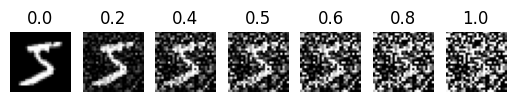

In [8]:
# Visualize images at different noisy level
# ===== your code here! ====
x, _ = train_dataset[0]  # (1, 28, 28)
sigmas = [0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0]
e = torch.randn_like(x)
fig, axes = plt.subplots(1, len(sigmas))
for ax, s in zip(axes, sigmas):
    z = x + s * e
    ax.imshow(z.squeeze(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{s}")
    ax.axis("off")
# ===== end of code ====

## Part 1.2.1: Training

For this part, we provide some structure code for training. It is very basic, so feel free to change them or add your code. In later section we won't provide any training or visualization structure code.

In [9]:
# Complete the recommended denoising hyperparameters from Section 1.2.1.
batch_size = 256
learning_rate = 1e-4
noise_level = 0.5
# hidden_dim = 128
hidden_dim = 64
num_epochs = 5

In [10]:
# MNIST train_dataset/test_dataset were loaded in setup.
# Build shuffled training and non-shuffled test DataLoaders.
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

In [12]:
# Define your model, optimizer, and loss
# ===== your code here! ====
model = UnconditionalUNet(1, hidden_dim).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
criterion = nn.MSELoss()
# ===== end of code ====

In [13]:
print("CUDA:", torch.cuda.is_available())
print("Device:", device)
print("Model device:", next(model.parameters()).device)
print("GPU:", torch.cuda.get_device_name(0))
print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")


torch.backends.cudnn.benchmark = True

CUDA: True
Device: cuda
Model device: cuda:0
GPU: Tesla T4
Parameters: 1,975,361


In [17]:
samples = torch.stack([test_dataset[i][0] for i in range(5)]).to(device)
samples_noised = samples + 0.5 * torch.randn_like(samples)
samples_hat = {}

In [18]:
from tqdm import tqdm

# The training loops
train_losses = []
for epoch in range(num_epochs):
    for i, (images, _) in enumerate(tqdm(train_loader)):

        # ===== your code here! ====

        images = images.to(device)
        noisy_images = images + noise_level * torch.randn_like(images)
        outputs = model(noisy_images)

        # ===== end of code ====

        loss = criterion(outputs, images)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    train_losses.append(loss.item())

    # more stuff to track epoch 1 vs 5 predictions
    if epoch in [0, 4]:
        model.eval()
        with torch.no_grad():
            samples_hat[epoch] = model(samples_noised).cpu()

100%|██████████| 235/235 [00:33<00:00,  7.11it/s]


In [1]:
# Visualize your training curve
# ===== your code here! ====

plt.figure()
plt.plot(train_losses, label="Training Loss")
plt.xlabel("Step")
plt.ylabel("Loss")
plt.title("UNet Denoiser")
plt.show()

# ===== end of code ====

NameError: name 'plt' is not defined

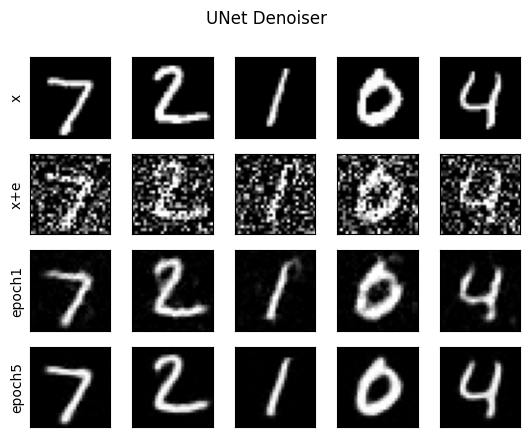

In [30]:
fig, axes = plt.subplots(4, 5)
rows = [samples.cpu(),samples_noised.cpu(),samples_hat[0],samples_hat[4]]
labels = ["x", "x+e", "epoch1", "epoch5"]

for row in range(4):
    for col in range(5):
        axes[row, col].imshow(rows[row][col].squeeze().numpy(),cmap="gray",vmin=0,vmax=1)
        # axes[row, col].axis("off")
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
    axes[row, 0].set_ylabel(labels[row], rotation=90)

plt.suptitle("UNet Denoiser")
plt.show()

## Part 1.2.2: Out-of-Distribution Testing

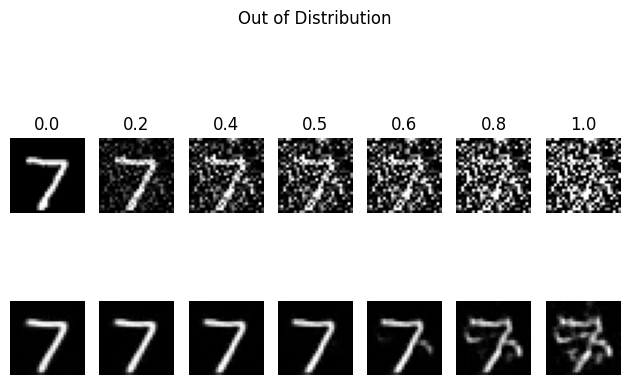

In [40]:
# Visualize OOD testing
# ===== your code here! ====
x, _ = test_dataset[0]
x = x.unsqueeze(0).to(device)
sigmas = [0.0, 0.2, 0.4, 0.5, 0.6, 0.8, 1.0]
e = torch.randn_like(x)
fig, axes = plt.subplots(2, len(sigmas))
model.eval()
with torch.no_grad():
    for i, s in enumerate(sigmas):
        z = x + s * e
        x_hat = model(z)
        axes[0, i].imshow(z.cpu().squeeze(), cmap="gray", vmin=0, vmax=1)
        axes[1, i].imshow(x_hat.cpu().squeeze(), cmap="gray", vmin=0, vmax=1)
        axes[0, i].set_title(f"{s}")
        axes[0, i].axis("off")
        axes[1, i].axis("off")

plt.suptitle("Out of Distribution")
plt.tight_layout()
plt.show()
# ===== end of code ====

## Part 1.2.3 Denoising Pure Noise

In [41]:
# COPY ABOVE
batch_size = 256
learning_rate = 1e-4
noise_level = 1.0
# hidden_dim = 128
hidden_dim = 64
num_epochs = 5
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
model = UnconditionalUNet(1, hidden_dim).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
criterion = nn.MSELoss()

In [49]:
# COPY ABOVE
samples_noised = torch.randn(5, 1, 28, 28, device=device)
samples_hat = {}

In [51]:
# COPY ABOVE
from tqdm import tqdm

# The training loops
train_losses = []
for epoch in range(num_epochs):
    for i, (images, _) in enumerate(tqdm(train_loader)):

        # ===== your code here! ====

        images = images.to(device)
        # noisy_images = images + noise_level * torch.randn_like(images)
        noise = torch.randn_like(images)
        outputs = model(noise)

        # ===== end of code ====

        loss = criterion(outputs, images)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    train_losses.append(loss.item())

    # more stuff to track epoch 1 vs 5 predictions
    if epoch in [0, 4]:
        model.eval()
        with torch.no_grad():
            samples_hat[epoch] = model(samples_noised).cpu()

100%|██████████| 235/235 [00:33<00:00,  7.09it/s]


In [2]:
# Visualize your training curve
# ===== your code here! ====

plt.figure()
plt.plot(train_losses, label="Training Loss")
plt.xlabel("Step")
plt.ylabel("Loss")
plt.title("UNet Denoiser (full noise)")
plt.show()

# ===== end of code ====

NameError: name 'plt' is not defined

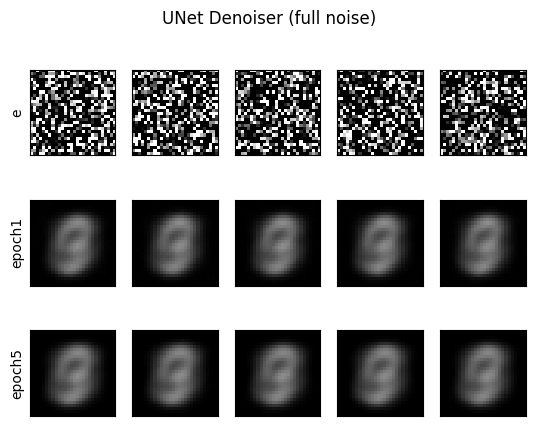

In [57]:
fig, axes = plt.subplots(3, 5)
rows = [samples_noised.cpu(),samples_hat[0],samples_hat[4]]
labels = ["e", "epoch1", "epoch5"]

for row in range(3):
    for col in range(5):
        axes[row, col].imshow(rows[row][col].squeeze().numpy(),cmap="gray",vmin=0,vmax=1)
        # axes[row, col].axis("off")
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
    axes[row, 0].set_ylabel(labels[row], rotation=90)

plt.suptitle("UNet Denoiser (full noise)")
plt.show()

# Part 2: Flow Matching

# Part 2.1: Implementing a Time-conditioned UNet

In [9]:
class FCBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        # ===== your code here! ====
        self.lin1 = nn.Linear(in_channels, out_channels)
        self.gelu = nn.GELU()
        self.lin2 = nn.Linear(out_channels, out_channels)
        # ===== end of code ====

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # ===== your code here! ====
        return self.lin2(self.gelu(self.lin1(x)))
        # ===== end of code ====
        raise NotImplementedError()


class TimeConditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_classes: int,
        num_hiddens: int,
    ):
        super().__init__()
        # ===== your code here! ====
        
        D = num_hiddens
        # Going down
        self.conv_in = ConvBlock(in_channels, D)
        self.e1 = DownBlock(D, D)
        self.e2 = DownBlock(D, 2*D)
        self.flatten = Flatten()
        # Going up
        self.unflatten = Unflatten(2*D)
        self.d1 = UpBlock(4*D, D)
        self.d2 = UpBlock(2*D, D)
        self.conv_out = ConvBlock(2*D, D)
        self.final = nn.Conv2d(D, in_channels, kernel_size=3, padding=1)
        # New time-conditioning
        self.t1 = FCBlock(1, 2*D)
        self.t2 = FCBlock(1, D)
        
        # ===== end of code ====

    def forward(
        self,
        x: torch.Tensor,
        t: torch.Tensor,
    ) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.
            t: (N,) normalized time tensor.

        Returns:
            (N, C, H, W) output tensor.
        """
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        # ===== your code here! ====

        e0 = self.conv_in(x)
        e1 = self.e1(e0)
        e2 = self.e2(e1)
        x = self.unflatten(self.flatten(e2))
        # Going up (with skips AND TIME!)
        t = t.reshape(-1, 1)
        t1 = self.t1(t).unsqueeze(-1).unsqueeze(-1)
        t2 = self.t2(t).unsqueeze(-1).unsqueeze(-1)
        
        x = x*t1
        x = torch.cat([x, e2], dim=1)
        x = self.d1(x)

        x = x*t2
        x = torch.cat([x, e1], dim=1)
        x = self.d2(x)

        x = torch.cat([x, e0], dim=1)
        x = self.conv_out(x)
        x = self.final(x)
        return x
        
        # ===== end of code ====
        raise NotImplementedError()

## Implementing the Forward and Reverse Process for Time-conditioned Denoising

In [10]:
def time_fm_forward(
    unet: TimeConditionalUNet,
    x_1: torch.Tensor,
    num_ts: int,
) -> torch.Tensor:
    """Algorithm 1

    Args:
        unet: TimeConditionalUNet
        x_1: (N, C, H, W) input tensor.
        num_ts: int, number of timesteps.
    Returns:
        (,) loss.
    """
    unet.train()
    # ===== your code here! ====

    x_0 = torch.randn_like(x_1)
    N = x_1.shape[0]
    t = torch.randint(0, num_ts, (N,), device=device)
    t = t/num_ts
    t_matrix = t[:,None,None,None]
    x_t = (1-t_matrix)*x_0 + t_matrix*x_1
    v_hat = unet(x_t, t)
    v = x_1 - x_0
    loss = F.mse_loss(v_hat, v)
    return loss

    # ===== end of code ====
    raise NotImplementedError()

In [28]:
@torch.inference_mode()
def time_fm_sample(
    unet: TimeConditionalUNet,
    img_wh: tuple[int, int],
    num_ts: int,
    seed: int = 0,
) -> torch.Tensor:
    """Algorithm 2

    Args:
        unet: TimeConditionalUNet
        img_wh: (H, W) output image width and height.
        num_ts: int, number of timesteps.
        seed: int, random seed.

    Returns:
        (N, C, H, W) final sample.
    """
    unet.eval()
    # ===== your code here! ====
    N = 40
    generator = torch.Generator(device=device).manual_seed(seed)
    x = torch.randn((N, 1, *img_wh),device=device,generator=generator)
    h = 1/num_ts
    for i in range(num_ts):
        t = torch.full((N,), i * h, device=device)
        v_hat = unet(x, t)
        x = x+h*v_hat
    return x

    # ===== end of code ====
    raise NotImplementedError()

In [30]:
class TimeConditionalFM(nn.Module):
    def __init__(
        self,
        unet: TimeConditionalUNet,
        num_ts: int = 50,
        img_hw: tuple[int, int] = (28, 28),
    ):
        super().__init__()

        self.unet = unet
        self.num_ts = num_ts
        self.img_hw = img_hw


    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.

        Returns:
            (,) flow-matching loss.
        """
        return time_fm_forward(
            self.unet, x, self.num_ts
        )


    @torch.inference_mode()
    def sample(
        self,
        img_wh: tuple[int, int],
        seed: int = 0,
    ):
        return time_fm_sample(
            self.unet, img_wh, self.num_ts, seed
        )

# Part 2.2: Training the Time-conditioned UNet

In [32]:
# COPY ABOVE
batch_size = 64
# batch_size = 256
learning_rate = 1e-2
hidden_dim = 64
# hidden_dim = 32
num_epochs = 10
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
unet = TimeConditionalUNet(in_channels=1,num_classes=10,num_hiddens=hidden_dim)
model = TimeConditionalFM(unet).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer,gamma=0.1 ** (1.0 / num_epochs))

In [34]:
    # COPY ABOVE
    from tqdm import tqdm
    
    # The training loops
    train_losses = []
    samples = {}
    for epoch in range(num_epochs):
        model.train()
        for i, (images, _) in enumerate(tqdm(train_loader)):
    
            # ===== your code here! ====
    
            images = images.to(device)
            loss = model(images)
    
            # ===== end of code ====
    
            # loss = criterion(outputs, images)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            train_losses.append(loss.item())
        scheduler.step()
        # more stuff to track epoch 1 vs 5 predictions
        if epoch in [0, 4, 9]:
            samples[epoch] = model.sample((28,28),seed=67).cpu()

100%|██████████| 938/938 [00:43<00:00, 21.80it/s]


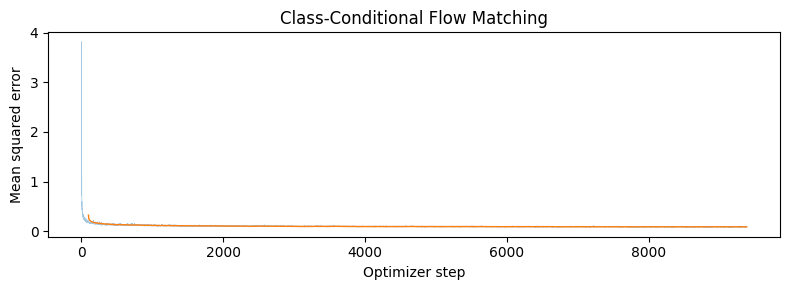

In [50]:
# COPY ABOVE
# Visualize your training curve
# ===== your code here! ====

# plt.figure()
# plt.plot(train_losses, label="Training Loss")
# plt.xlabel("Step")
# plt.ylabel("Loss")
# plt.title("Flow matching")
# plt.show()

# ===== end of code ====



loss_plot(train_losses, "Class-Conditional Flow Matching")

# Part 2.3: Sampling from the Time-conditioned UNet

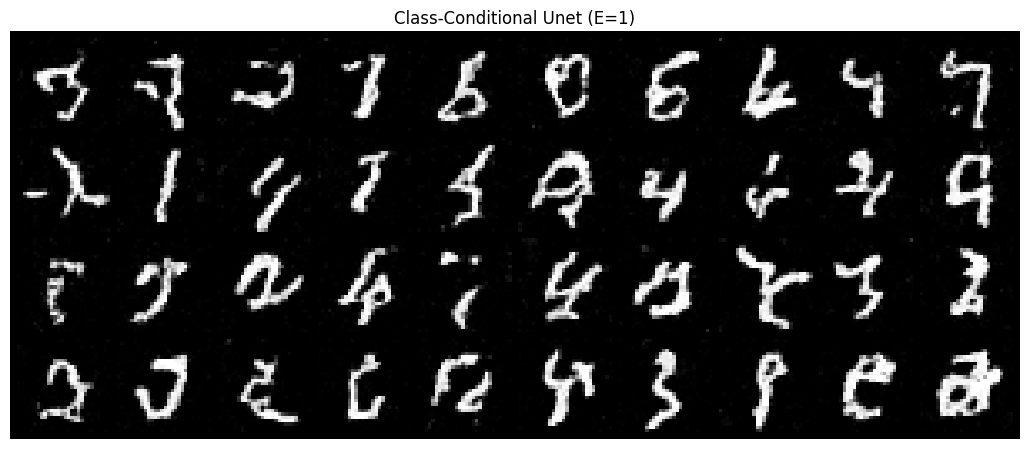

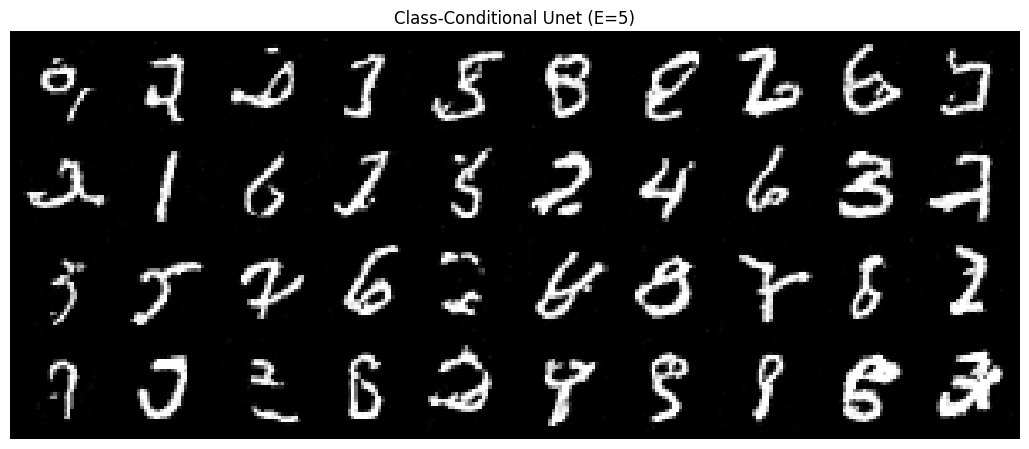

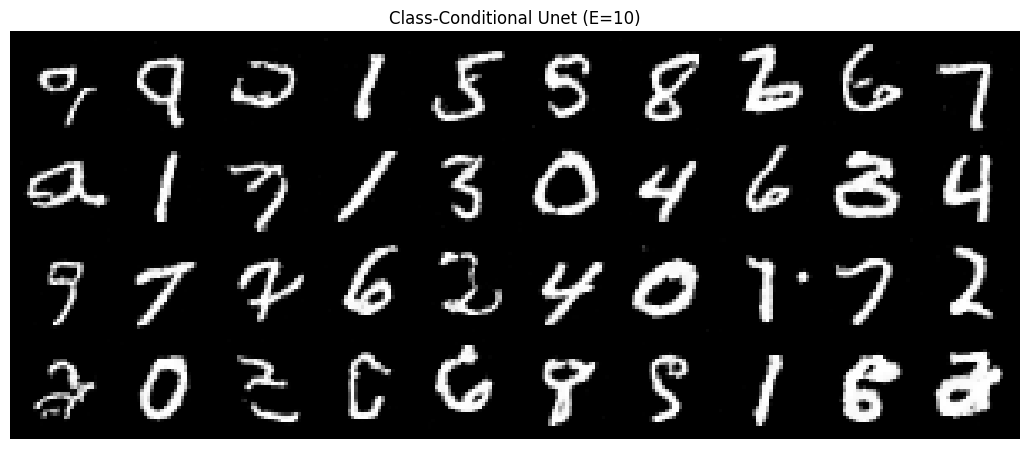

In [44]:
# # Sampling from the UNet
# # ===== your code here! ====
# fig, axes = plt.subplots(3, 5)
# for r, ep in enumerate([0, 4, 9]):
#     for c in range(5):
#         axes[r, c].imshow(
#             samples[ep][c].squeeze(),
#             cmap="gray",vmin=0,vmax=1)
#         axes[r, c].axis("off")
#         axes[row, col].set_xticks([])
#     axes[r, 0].set_ylabel(f"Epoch{ep+1}", fontsize=12)

# plt.suptitle("Time-Conditioned UNet")
# plt.show()
# # ===== end of code ====

show_grid(
    samples[0],
    title="Class-Conditional Unet (E=1)",
    filename="2.3.1.png",
    nrow=10
)

show_grid(
    samples[4],
    title="Class-Conditional Unet (E=5)",
    filename="2.3.5.png",
    nrow=10
)

show_grid(
    samples[9],
    title="Class-Conditional Unet (E=10)",
    filename="2.3.10.png",
    nrow=10
)

# Part 2.4: Implementing a Class-conditioned UNet

In [56]:
class ClassConditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels: int,
        num_classes: int,
        num_hiddens: int,
    ):
        super().__init__()
        # ===== your code here! ====

        self.D = num_hiddens
        D = num_hiddens
        # Going down
        self.conv_in = ConvBlock(in_channels, D)
        self.e1 = DownBlock(D, D)
        self.e2 = DownBlock(D, 2*D)
        self.flatten = Flatten()
        # Going up
        self.unflatten = Unflatten(2*D)
        self.d1 = UpBlock(4*D, D)
        self.d2 = UpBlock(2*D, D)
        self.conv_out = ConvBlock(2*D, D)
        self.final = nn.Conv2d(D, in_channels, kernel_size=3, padding=1)
        # New time-conditioning
        self.t1 = FCBlock(1, 2*D)
        self.t2 = FCBlock(1, D)
        # New class-conditioning
        self.C = num_classes
        C = num_classes
        self.c1 = FCBlock(C, 2*D)
        self.c2 = FCBlock(C, D)
        # ===== end of code ====

    def forward(
        self,
        x: torch.Tensor,
        c: torch.Tensor,
        t: torch.Tensor,
        mask: Optional[torch.Tensor] = None,
    ) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.
            c: (N,) int64 condition tensor.
            t: (N,) normalized time tensor.
            mask: (N,) mask tensor. If not None, mask out condition when mask == 0.

        Returns:
            (N, C, H, W) output tensor.
        """
        assert x.shape[-2:] == (28, 28), "Expect input shape to be (28, 28)."
        # ===== your code here! ====
        e0 = self.conv_in(x)
        e1 = self.e1(e0)
        e2 = self.e2(e1)
        x = self.unflatten(self.flatten(e2))
        # Going up (with skips AND TIME AND CLASS!)
        t = t.reshape(-1, 1)
        t1 = self.t1(t).unsqueeze(-1).unsqueeze(-1)
        t2 = self.t2(t).unsqueeze(-1).unsqueeze(-1)
        c = F.one_hot(c, num_classes=self.C).float()
        if mask is not None:
            c = c * mask.reshape(-1, 1)
        c1 = self.c1(c).unsqueeze(-1).unsqueeze(-1)
        c2 = self.c2(c).unsqueeze(-1).unsqueeze(-1)
        
        x = c1*x+t1
        x = torch.cat([x, e2], dim=1)
        x = self.d1(x)

        x = c2*x+t2
        x = torch.cat([x, e1], dim=1)
        x = self.d2(x)

        x = torch.cat([x, e0], dim=1)
        x = self.conv_out(x)
        x = self.final(x)
        return x
        # ===== end of code ====
        raise NotImplementedError()

In [57]:
def class_fm_forward(
    unet: ClassConditionalUNet,
    x_1: torch.Tensor,
    c: torch.Tensor,
    p_uncond: float,
    num_ts: int,
) -> torch.Tensor:
    """Algorithm 3

    Args:
        unet: ClassConditionalUNet
        x_1: (N, C, H, W) input tensor.
        c: (N,) int64 condition tensor.
        p_uncond: float, probability of unconditioning the condition.
        num_ts: int, number of timesteps.

    Returns:
        (,) loss.
    """
    unet.train()
    # ===== your code here! ====

    x_0 = torch.randn_like(x_1)
    N = x_1.shape[0]
    t = torch.randint(0, num_ts, (N,), device=device)
    t = t/num_ts
    t_matrix = t[:,None,None,None]
    x_t = (1-t_matrix)*x_0 + t_matrix*x_1
    mask = (torch.rand(N, device=device) > p_uncond)
    v_hat = unet(x_t, c, t, mask=mask)
    v = x_1 - x_0
    loss = F.mse_loss(v_hat, v)
    return loss
    
    # ===== end of code ====
    raise NotImplementedError()

In [58]:
@torch.inference_mode()
def class_fm_sample(
    unet: ClassConditionalUNet,
    c: torch.Tensor,
    img_wh: tuple[int, int],
    num_ts: int,
    guidance_scale: float = 5.0,
    seed: int = 0,
) -> torch.Tensor:
    """Algorithm 4

    Args:
        unet: ClassConditionalUNet
        c: (N,) int64 condition tensor. Only for class-conditional
        img_wh: (H, W) output image width and height.
        num_ts: int, number of timesteps.
        guidance_scale: float, CFG scale.
        seed: int, random seed.

    Returns:
        (N, C, H, W) final sample.
        (N, T_animation, C, H, W) caches.
    """
    unet.eval()
    # ===== your code here! ====

    c = c.to(device)
    N = c.shape[0]
    generator = torch.Generator(device=device).manual_seed(seed)
    x = torch.randn((N, 1, *img_wh),device=device,generator=generator)
    h = 1/num_ts
    caches = []
    for i in range(num_ts):
        t = torch.full((N,), i * h, device=device)
        mask_u = torch.zeros(N, device=device)
        mask_c = torch.ones(N, device=device)
        v_u = unet(x, c, t, mask_u)
        v_c = unet(x, c, t, mask_c)
        v = v_u + guidance_scale*(v_c - v_u)
        x = x+h*v
        caches.append(x.detach().cpu())
    caches = torch.stack(caches, dim=1)
    return x, caches

    # ===== end of code ====
    raise NotImplementedError()

In [59]:
class ClassConditionalFM(nn.Module):
    def __init__(
        self,
        unet: ClassConditionalUNet,
        num_ts: int = 300,
        p_uncond: float = 0.1,
    ):
        super().__init__()
        self.unet = unet
        self.num_ts = num_ts
        self.p_uncond = p_uncond

    def forward(self, x: torch.Tensor, c: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (N, C, H, W) input tensor.
            c: (N,) int64 condition tensor.

        Returns:
            (,) loss.
        """
        return class_fm_forward(
            self.unet, x, c, self.p_uncond, self.num_ts
        )

    @torch.inference_mode()
    def sample(
        self,
        c: torch.Tensor,
        img_wh: tuple[int, int],
        guidance_scale: float = 5.0,
        seed: int = 0,
    ):
        return class_fm_sample(
            self.unet, c, img_wh, self.num_ts, guidance_scale, seed
        )

# Part 2.5 Training the Class-conditioned UNet

In [60]:
# Train a fresh class-conditioned D=64 UNet for 10 epochs, batch size 64,
# Adam initial lr=1e-2, class dropout probability .1, exponential gamma=.1**(1/10).
# Save checkpoints at epochs 1,5,10. Then train an independent no-scheduler
# comparison; choose/document a constant learning rate and compare results.


batch_size = 64
# batch_size = 256
learning_rate = 1e-2
hidden_dim = 64
# hidden_dim = 32
num_epochs = 10
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
unet = ClassConditionalUNet(in_channels=1,num_classes=10,num_hiddens=hidden_dim)
model = ClassConditionalFM(unet).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer,gamma=0.1 ** (1.0 / num_epochs))


In [61]:
# COPY ABOVE
from tqdm import tqdm

# The training loops
train_losses = []
samples = {}
classes = torch.arange(40, device=device) // 4
for epoch in range(num_epochs):
    model.train()
    for i, (images, labels) in enumerate(tqdm(train_loader)):

        # ===== your code here! ====

        images = images.to(device)
        labels = labels.to(device)
        loss = model(images, labels)

        # ===== end of code ====

        # loss = criterion(outputs, images)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_losses.append(loss.item())
    scheduler.step()
    # more stuff to track epoch 1 vs 5 predictions
    if epoch in [0, 4, 9]:
        x, cache = model.sample(classes,(28, 28),seed=67)
        torch.save(model.state_dict(), OUT / f"classcond_{epoch+1}.pt")
        samples[epoch] = x.cpu()

100%|██████████| 938/938 [00:43<00:00, 21.58it/s]


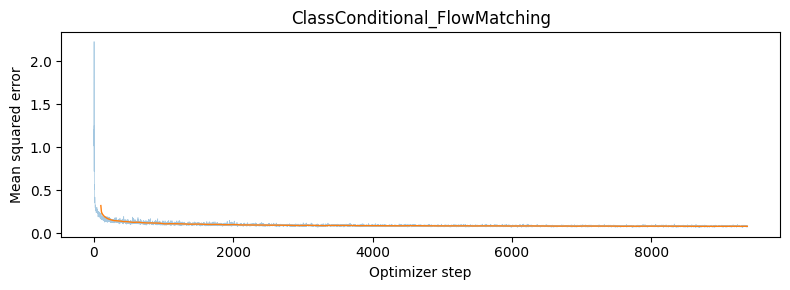

In [64]:
loss_plot(train_losses, "ClassConditional_FlowMatching")

# Part 2.6: Sampling from the Class-conditioned UNet

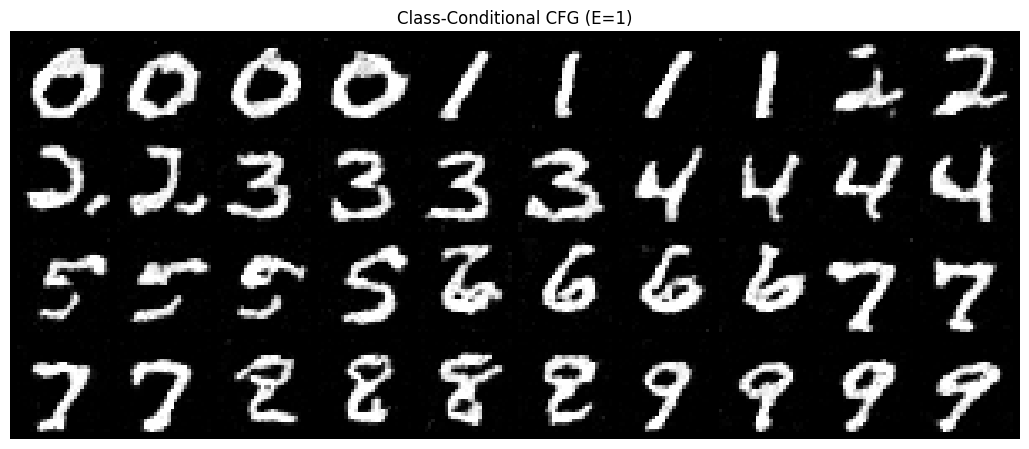

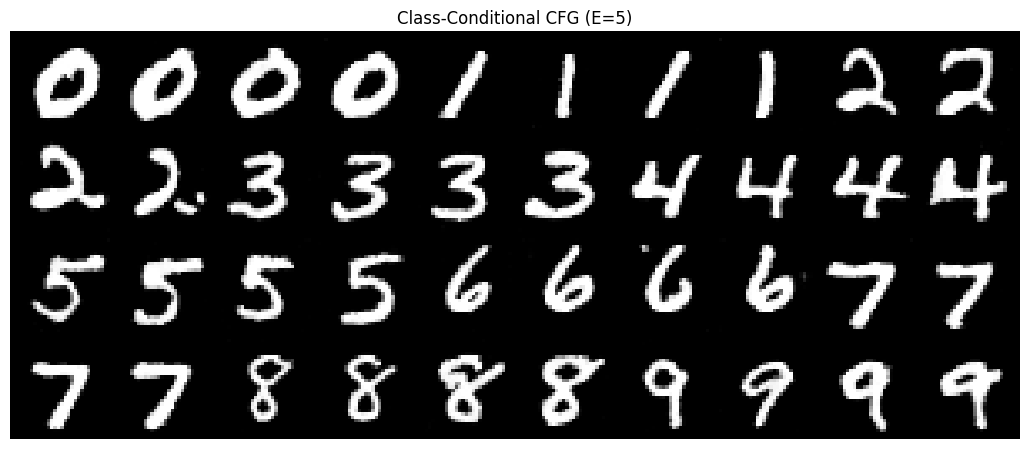

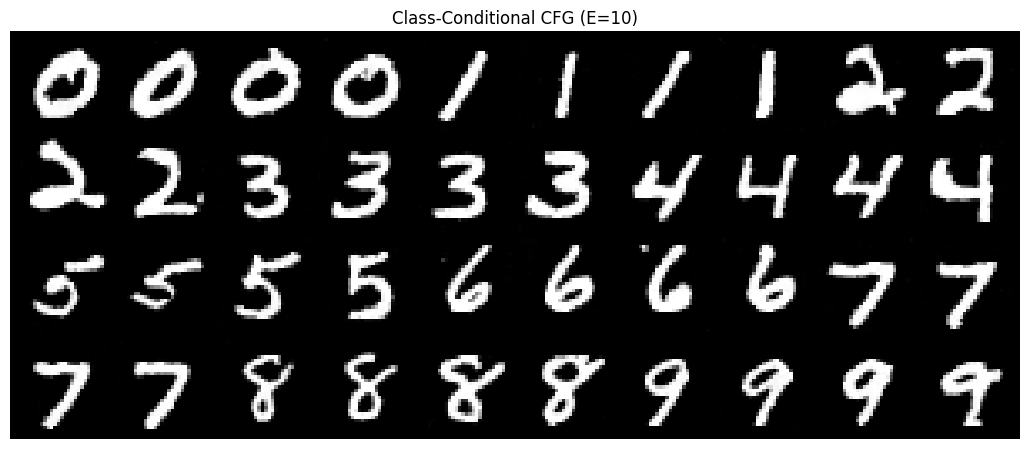

In [65]:
# At epochs 1,5,10, generate four instances of each digit (40 images),
# with 300 Euler steps and guidance scale 5.0. Keep seeds fixed for comparisons.
# Also visualize the no-scheduler model and describe the tradeoff.

show_grid(
    samples[0],
    title="Class-Conditional CFG (E=1)",
    filename="2.6.1.png",
    nrow=10
)

show_grid(
    samples[4],
    title="Class-Conditional CFG (E=5)",
    filename="2.6.5.png",
    nrow=10
)

show_grid(
    samples[9],
    title="Class-Conditional CFG (E=10)",
    filename="2.6.10.png",
    nrow=10
)

In [66]:
batch_size = 64
learning_rate = 3e-3
hidden_dim = 64
num_epochs = 10
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
unet = ClassConditionalUNet(in_channels=1,num_classes=10,num_hiddens=hidden_dim)
model = ClassConditionalFM(unet).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
# scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer,gamma=0.1 ** (1.0 / num_epochs))



train_losses = []
samples = {}
classes = torch.arange(40, device=device) // 4
for epoch in range(num_epochs):
    model.train()
    for i, (images, labels) in enumerate(tqdm(train_loader)):

        # ===== your code here! ====

        images = images.to(device)
        labels = labels.to(device)
        loss = model(images, labels)

        # ===== end of code ====

        # loss = criterion(outputs, images)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_losses.append(loss.item())
    # scheduler.step()
    # more stuff to track epoch 1 vs 5 predictions
    if epoch in [0, 4, 9]:
        x, cache = model.sample(classes,(28, 28),seed=67)
        torch.save(model.state_dict(), OUT / f"classcond_nosched_{epoch+1}.pt")
        samples[epoch] = x.cpu()

100%|██████████| 938/938 [00:43<00:00, 21.59it/s]


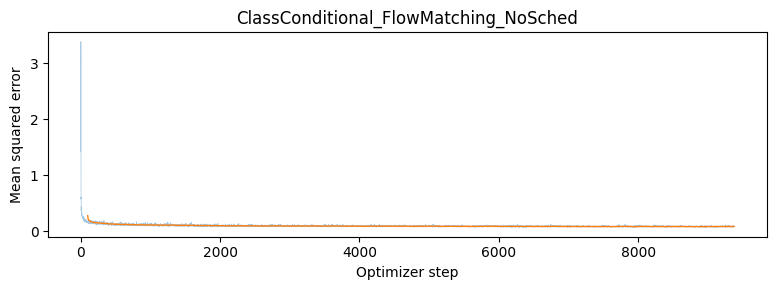

In [67]:
loss_plot(train_losses, "ClassConditional_FlowMatching_NoSched")
show_grid(
    samples[9],
    title="No Sched CFG (E=10)",
    filename="2.6.10.nosched.png",
    nrow=10
)